# 4. Ensemble learning
Bagging (Random Forest), boosting (AdaBoost, Gradient Boosting, XGBoost), soft voting and stacking.

In [1]:
from pathlib import Path
import json, pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
ROOT = Path.cwd() if (Path.cwd()/'data').exists() else Path.cwd().parent
RES = ROOT/'results'; sns.set_theme(style='whitegrid')
s = pd.read_csv(RES/'summary.csv')
e = s[s.family=='Ensemble']
e.pivot(index='model', columns='condition', values='cv_accuracy_mean').round(4)

condition,Original 30,PCA 95%,SelectKBest 15
model,,,
AdaBoost,0.9344,0.9092,0.9295
Gradient Boosting,0.9438,0.9252,0.9380
Random Forest,0.9440,0.9254,0.9382
Soft Voting,0.9196,0.9250,0.9154
Stacking,0.9395,0.9329,0.9297
XGBoost,0.9500,0.9335,0.9374


            mean     max
family                  
Base      0.8841  0.9374
Ensemble  0.9317  0.9500


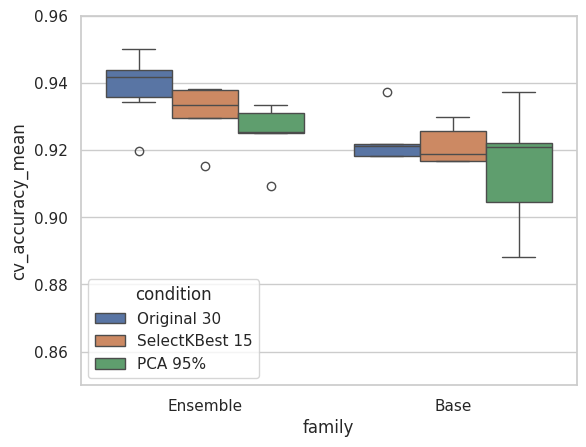

In [2]:
print(s.groupby('family').cv_accuracy_mean.agg(['mean','max']).round(4))
sns.boxplot(data=s, x='family', y='cv_accuracy_mean', hue='condition'); plt.ylim(0.85,0.96); plt.show()

**Observation:** the top 4 configurations are all ensembles on the original 30 features, led by XGBoost (~95.0%). Boosting/bagging beat the best single model (SVM, ~93.7%) by over a point. Soft Voting is weaker than its best member because it includes Gaussian NB.